In [11]:
# import wfdb
# import pandas as pd
# import matplotlib.pyplot as plt
# import numpy as np

# # Stream record
# record = wfdb.rdrecord(
#     r"D:/SynGen/dataset/records100/00000"
# )

# signal = record.p_signal   # (1000, 12)
# fs = record.fs             # 100
# leads = record.sig_name    # ['I', 'II', ...]

# # Build time axis in seconds
# time = np.arange(signal.shape[0]) / fs  # 0.00, 0.01, 0.02 ... 9.99

# # Plot all 12 leads stacked
# fig, axes = plt.subplots(12, 1, figsize=(15, 20), sharex=True)

# for i, ax in enumerate(axes):
#     ax.plot(time, signal[:, i], linewidth=0.8)
#     ax.set_ylabel(leads[i], fontsize=9)
#     ax.grid(True, alpha=0.3)

# axes[-1].set_xlabel('Time (seconds)')
# plt.suptitle('PTB-XL ECG — All 12 Leads', fontsize=13)
# plt.tight_layout()
# plt.show()/

import wfdb
import os
import numpy as np

folder = r"D:/SynGen/dataset/records100/04000"

# get all .hea files
files = [f for f in os.listdir(folder) if f.endswith('.hea')]

all_signals = []

for file in files:
    record_name = file.replace('.hea', '')
    
    path = os.path.join(folder, record_name)
    
    record = wfdb.rdrecord(path)
    
    signal = record.p_signal  # (1000, 12)
    
    all_signals.append(signal)

# convert to numpy array
all_signals = np.array(all_signals)

print("Final shape:", all_signals.shape)

Final shape: (1000, 1000, 12)


In [18]:
all_signals

array([[[-0.135, -0.035,  0.1  , ..., -0.016, -0.081,  0.155],
        [-0.134, -0.035,  0.099, ..., -0.02 , -0.088,  0.154],
        [-0.124, -0.031,  0.093, ..., -0.02 , -0.091,  0.15 ],
        ...,
        [ 0.188,  0.16 , -0.028, ...,  0.125,  0.181,  0.193],
        [ 0.276,  0.121, -0.156, ...,  0.129,  0.106,  0.018],
        [ 0.379,  0.084, -0.295, ...,  0.075,  0.062,  0.303]],

       [[-0.064, -0.069, -0.005, ...,  0.09 , -0.029,  0.2  ],
        [-0.042, -0.05 , -0.008, ...,  0.093, -0.007,  0.201],
        [-0.045, -0.05 , -0.005, ...,  0.096,  0.017,  0.205],
        ...,
        [-0.01 ,  0.024,  0.034, ..., -0.143, -0.174,  0.066],
        [ 0.025,  0.076,  0.051, ..., -0.112, -0.16 ,  0.079],
        [ 0.005,  0.04 ,  0.035, ..., -0.107, -0.113,  0.059]],

       [[ 0.055,  0.219,  0.164, ..., -0.013, -0.145,  0.006],
        [ 0.071,  0.223,  0.152, ..., -0.002, -0.135,  0.011],
        [ 0.09 ,  0.212,  0.122, ..., -0.021, -0.137,  0.021],
        ...,
        [-0.

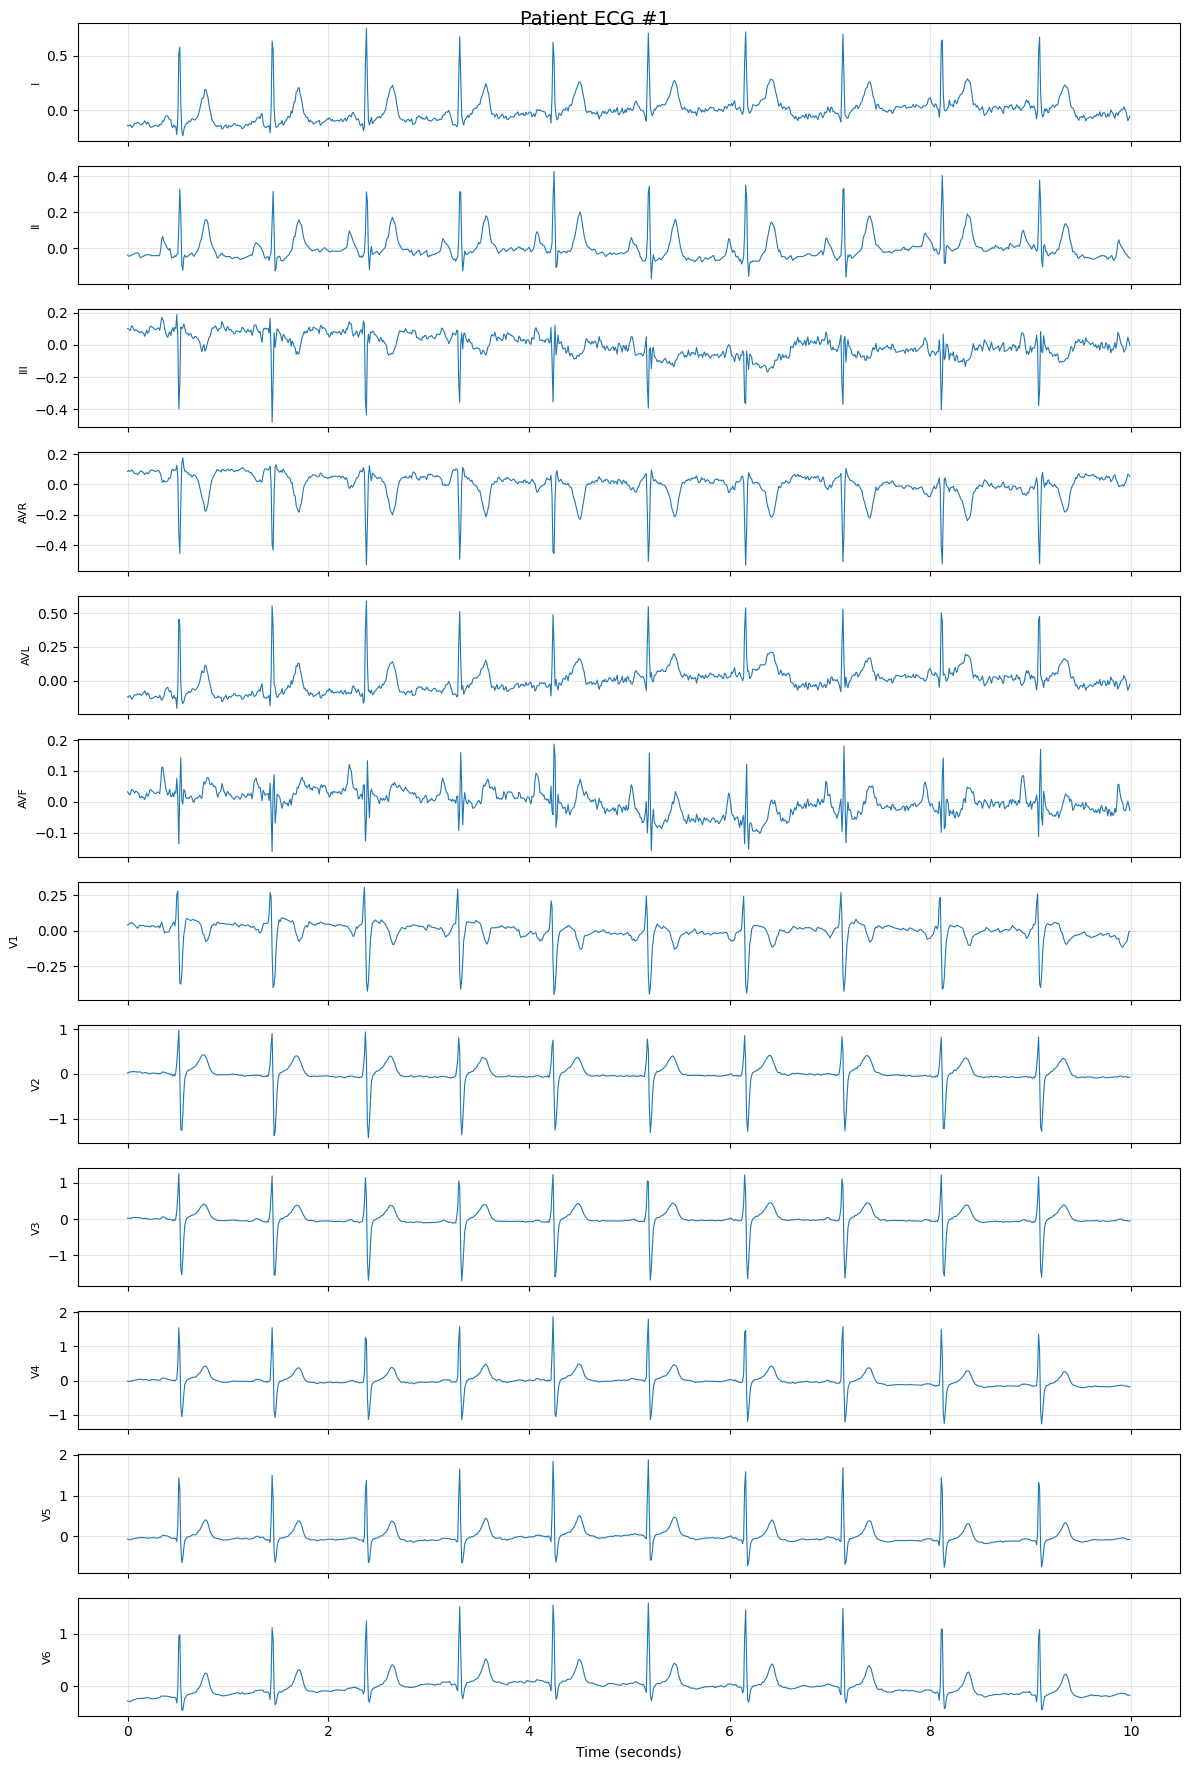

In [17]:
import matplotlib.pyplot as plt
import numpy as np

# assuming all_signals = (n_records, 1000, 12)
fs = 100  # sampling frequency

time = np.arange(1000) / fs
lead = record.sig_name

for idx, signal in enumerate(all_signals[8:9]):  # show first 5 patients
    
    fig, axes = plt.subplots(12, 1, figsize=(12, 18), sharex=True)
    
    for i, ax in enumerate(axes):
        ax.plot(time, signal[:, i], linewidth=0.8)
        ax.set_ylabel(lead[i], fontsize=8)
        ax.grid(True, alpha=0.3)
    
    axes[-1].set_xlabel('Time (seconds)')
    plt.suptitle(f'Patient ECG #{idx+1}', fontsize=14)
    
    plt.tight_layout()
    plt.show()

In [ ]:
record.dac

array([[-0.069, -0.005,  0.064, ..., -0.315, -0.22 , -0.275],
       [-0.07 , -0.005,  0.065, ..., -0.315, -0.218, -0.274],
       [-0.087, -0.005,  0.082, ..., -0.311, -0.211, -0.269],
       ...,
       [-0.072,  0.03 ,  0.102, ..., -0.121, -0.203, -0.146],
       [ 0.071,  0.215,  0.145, ...,  0.515,  0.27 ,  0.148],
       [ 0.285,  0.588,  0.303, ...,  1.511,  1.237,  0.808]],
      shape=(1000, 12))